In [1]:
!pip install scikit-learn

In [2]:
!pip install --upgrade certifi

In [11]:
import pandas as pd
import numpy as np

import ssl
ssl._create_default_https_context = ssl._create_unverified_context # ssl 인증서 검증 비활성화(ssl: certificate_verify_failed 오류 해결 위함)

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None) # 주소도 가능. \s+: 공백 1개 이상. skiprows=22: 22줄 이후부터.
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]]) # 수평으로 concat. 짝수행의 모든 열([::2, :])과 홀수행의 0과 1열([1::2, :2])
target = raw_df.values[1::2, 2] # 홀수행의 2열이 종속변수

print(target.shape) # 현재는 일차원 배열. (506,)

target = target.reshape(-1, 1) # 열의 개수는 1개로, 행의 개수는 원소의 수 맞춰서. --> 열 벡터로 변환
print(target.shape) # 열 벡터. (506, 1)

combined_data = np.hstack([data, target])

boston_df = pd.DataFrame(combined_data)
column_names = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "PRICE"]

boston_df.columns = column_names
print('보스톤 주택 가격 데이터셋 크기: ', boston_df.shape)
print(boston_df.info())

boston_df.to_csv("output.csv", index = False, encoding = 'utf-8-sig')

(506,)
(506, 1)
보스톤 주택 가격 데이터셋 크기:  (506, 14)
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  PRICE    506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB
None


In [18]:
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

boston_df = pd.read_csv("output.csv", sep = ",", header = 0, encoding = 'utf-8')
display(boston_df.head())

# X, Y 분할
Y = boston_df['PRICE']
X = boston_df.drop(['PRICE'], axis = 1, inplace = False) # 원본 데이터프레임 자체는 갱신하지 않음!

# 훈련용 데이터와 평가용 데이터 분할
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 156) # 시드값 고정 -> 분리가 항상 동일하게.

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [20]:
lr = LinearRegression()
lr.fit(X_train, Y_train); # _repr_html_ 출력을 억제해, 시각화하려다 내부에서 UnicoeDecodeError가 일어나는 것을 방지

In [25]:
# 선형 회귀 분석: 평가 데이터 예측 -> Y_predict 구하기
Y_predict = lr.predict(X_test)

temp_df = X_test.copy()
temp_df['PRICE'] = Y_test
temp_df['Y_HAT'] = Y_predict

display(temp_df.head())

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE,Y_HAT
210,0.17446,0.0,10.59,1.0,0.489,5.960,92.1,3.8771,4.0,277.0,18.6,393.25,17.27,21.7,23.154241
15,0.62739,0.0,8.14,0.0,0.538,5.834,56.5,4.4986,4.0,307.0,21.0,395.62,8.47,19.9,19.655902
264,0.55007,20.0,3.97,0.0,0.647,7.206,91.6,1.9301,5.0,264.0,13.0,387.89,8.10,36.5,36.420052
396,5.87205,0.0,18.10,0.0,0.693,6.405,96.0,1.6768,24.0,666.0,20.2,396.90,19.37,12.5,19.967051
234,0.44791,0.0,6.20,1.0,0.507,6.726,66.5,3.6519,8.0,307.0,17.4,360.20,8.05,29.0,32.401506


In [26]:
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse) # root MSE(MSE에 루트)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse, rmse)) # 인자 위치 지정. 소수점 셋째자리까지 출력.
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_test, Y_predict)))

MSE: 17.297, RMSE: 4.159
R^2(Variance score) : 0.757


In [28]:
print('Y 절편 값: ', lr.intercept_) # bias
print('회귀 계수 값: ', np.round(lr.coef_, 1)) # weight. 소수점 첫째자리까지.

# 참고) 0. : 가중치 있는 것(첫째자리 이후에 있어서, 첫째자리까지만 출력한 지금은 안 보일 뿐)

Y 절편 값:  40.99559517216497
회귀 계수 값:  [ -0.1   0.1   0.    3.  -19.8   3.4   0.   -1.7   0.4  -0.   -0.9   0.
  -0.6]


In [30]:
coef = pd.Series(data = np.round(lr.coef_, 2), index = X.columns) # 피처 이름을 인덱스로 지정
coef.sort_values(ascending = False) # 내림차순

# 오래된 주택의 비율(AGE)은 생각보다 큰 영향이 없군(0.01)
# 일산화질소의 농도(NOX)는 가격에 악영향을 미치는군(-19.80)

RM          3.35
CHAS        3.05
RAD         0.36
ZN          0.07
INDUS       0.03
AGE         0.01
B           0.01
TAX        -0.01
CRIM       -0.11
LSTAT      -0.57
PTRATIO    -0.92
DIS        -1.74
NOX       -19.80
dtype: float64

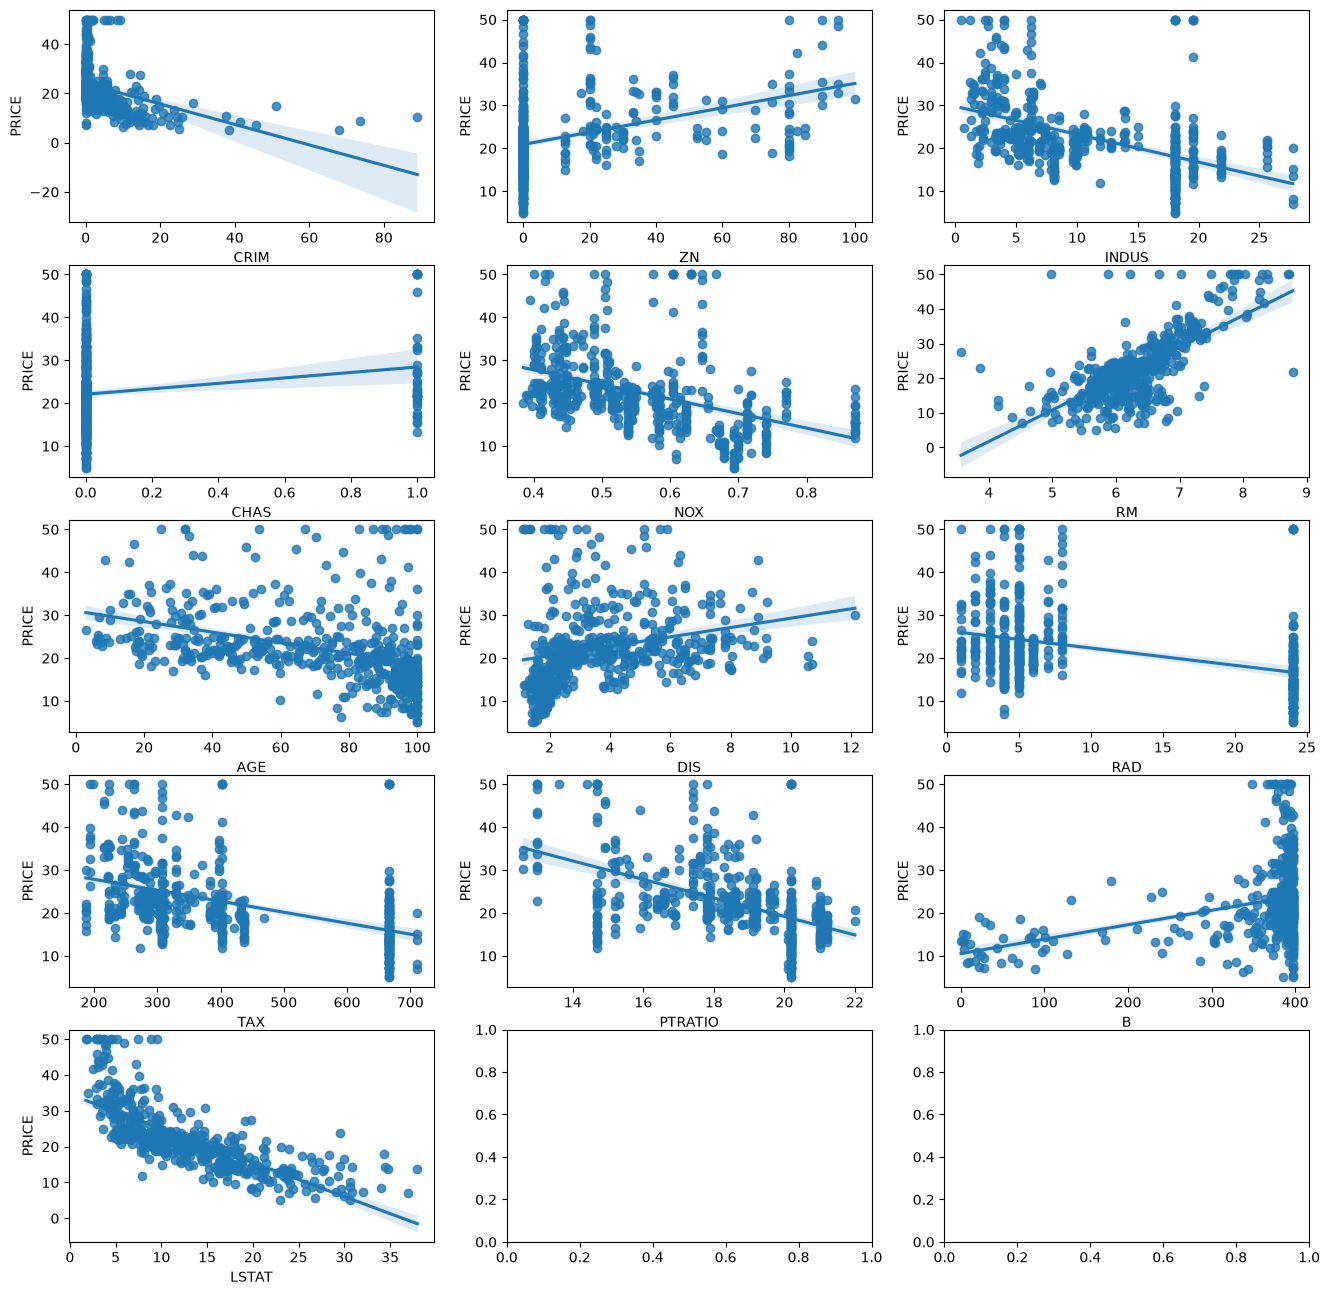

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(figsize = (16, 16), ncols = 3, nrows = 5)

x_features = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

for i, feature in enumerate(x_features): # 반복 가능한 객체 다룰 때 (인덱스, 원소값) 하나씩 꺼냄.
    row = int(i/3)
    col = i%3
    sns.regplot(x = feature, y = 'PRICE', data = boston_df, ax = axs[row][col]) # 산점도(scatter plot)와 선형 회귀 그래프(line plot) 함께 그림.
plt.show()

# CRIM(지역별 범죄 발생률)은 PRICE와 음의 상관 관계에 있군.
# RM(방 개수. 곧 집 크기)은 PRICE와 양의 상관 관계에 있군.
# AGE는 PRICE와 음의 상관 관계에 있는데, 영향은 적군.